# Examen Práctico — Primer Parcial
## Tópicos de Big Data

**Instrucciones generales**

- Este notebook es tu entregable. Complétalo en orden, sin borrar los enunciados.
- Al final debes subir este archivo (`.ipynb`) al repositorio de GitHub del curso, en la carpeta correspondiente a tu nombre/usuario.
- Se evaluará tanto el código (que corra sin errores, de arriba hacia abajo) como tus interpretaciones escritas en las celdas de texto marcadas como *"Interpretación"*.
- Cada quien trabaja con **un dataset distinto**, asignado por la profesora. No copies celdas de un compañero con un dataset diferente: aunque las preguntas se parecen, los datos y las columnas no son las mismas.


## 0. Datos del alumno

Completa la siguiente celda con tus datos y el nombre del dataset que te fue asignado.

In [1]:
NOMBRE = "Sebastian Arreguin Villanueva"
MATRICULA = "81841"
DATASET_ASIGNADO = "migracion"

print(f"Alumno: {NOMBRE}")
print(f"Matrícula: {MATRICULA}")
print(f"Dataset asignado: {DATASET_ASIGNADO}")


Alumno: Sebastian Arreguin Villanueva
Matrícula: 81841
Dataset asignado: migracion


## 1. Configuración del entorno virtual

El entorno virtual fue creado con:

```powershell
python -m venv .venv
.venv\Scripts\Activate.ps1
pip install pandas numpy ipykernel matplotlib requests
```


In [2]:
import sys
print(sys.executable)


C:\Users\sebar\Documents\BIG_DATA_512\EXAMEN_1P_512\.venv\Scripts\python.exe


## 2. Configuración y carga de datos


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

DATASETS = {
    "alcohol": {
        "csv": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "alcohol__consumers_past_12_months__pct__age_standardized__sex_both_sexes",
        "filtro_paises": "code",
        "descripcion": "Porcentaje de adultos (15+) que bebieron alcohol en el ultimo anio",
        "unidad": "%",
    },
    "migracion": {
        "csv": "https://ourworldindata.org/grapher/migrant-populations.csv?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "meta": "https://ourworldindata.org/grapher/migrant-populations.metadata.json?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "valor_col": "immigrants_all",
        "filtro_paises": "owid_region",
        "descripcion": "Numero total de inmigrantes internacionales residiendo en el pais",
        "unidad": "personas",
    },
    "desnutricion": {
        "csv": "https://ourworldindata.org/grapher/number-undernourished.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/number-undernourished.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "_2_1_1_number_of_undernourished_people__000000000024001__value__006132__millions",
        "filtro_paises": "code",
        "descripcion": "Numero de personas subalimentadas (desnutricion)",
        "unidad": "personas",
    },
    "pib": {
        "csv": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "ny_gdp_pcap_kd",
        "filtro_paises": "code",
        "descripcion": "PIB per capita (dolares constantes de 2015)",
        "unidad": "USD",
    },
    "homicidios": {
        "csv": "https://ourworldindata.org/grapher/homicides-unodc.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/homicides-unodc.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "value__category_total__sex_total__age_total__unit_of_measurement_counts",
        "filtro_paises": "owid_region",
        "descripcion": "Numero de homicidios intencionales por anio",
        "unidad": "homicidios",
    },
}

assert DATASET_ASIGNADO in DATASETS
config = DATASETS[DATASET_ASIGNADO]
print(f"Cargando dataset: {DATASET_ASIGNADO}")
print(f"Descripcion: {config['descripcion']} ({config['unidad']})")


Cargando dataset: migracion
Descripcion: Numero total de inmigrantes internacionales residiendo en el pais (personas)


In [4]:
df = pd.read_csv(
    config["csv"],
    storage_options={"User-Agent": "Our World In Data data fetch/1.0"}
)
metadata = requests.get(config["meta"]).json()
df = df.rename(columns={config["valor_col"]: "valor"})


In [5]:
df.head(25)


,entity,code,year,valor,owid_region
0,Afghanistan,AFG,1990,57686,Asia
1,Afghanistan,AFG,1995,71522,Asia
2,Afghanistan,AFG,2000,75917,Asia
3,Afghanistan,AFG,2005,87314,Asia
4,Afghanistan,AFG,2010,102276,Asia
5,Afghanistan,AFG,2015,339432,Asia
6,Afghanistan,AFG,2020,144098,Asia
7,Afghanistan,AFG,2024,98110,Asia
8,Africa,OWID_AFR,1990,16176915,NaN
9,Africa,OWID_AFR,1995,16653698,NaN


## 3. Exploración inicial


In [6]:
df.shape


(2144, 5)

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2144 entries, 0 to 2143
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   entity       2144 non-null   str  
 1   code         1960 non-null   str  
 2   year         2144 non-null   int64
 3   valor        2144 non-null   int64
 4   owid_region  1824 non-null   str  
dtypes: int64(2), str(3)
memory usage: 83.9 KB


In [8]:
df["valor"].describe()


count    2.144000e+03
mean     4.987920e+06
std      1.998549e+07
min      1.080000e+02
25%      3.905450e+04
50%      2.187635e+05
75%      1.420072e+06
max      3.040218e+08
Name: valor, dtype: float64

In [9]:
df.isnull().sum()


entity           0
code           184
year             0
valor            0
owid_region    320
dtype: int64

**Interpretación:** El dataset contiene observaciones de multiples anios. Para la migracion, `owid_region` tiene un valor para paises reales y es NaN para agregados (continentes).

## 4. Preguntas de análisis


### Pregunta 1 — Filtrado de países reales y ranking


In [10]:
# Pregunta 1
filtro_col = config["filtro_paises"]
df_paises = df[df[filtro_col].notnull()].copy()
num_paises = df_paises["entity"].nunique()
print(f"Numero de paises distintos: {num_paises}")
anio_max = df_paises.dropna(subset=["valor"])["year"].max()
print(f"Anio mas reciente con datos: {anio_max}")
df_reciente = df_paises[df_paises["year"] == anio_max].dropna(subset=["valor"])
print("\nTop 10 paises con MAYOR numero de inmigrantes:")
print(df_reciente.sort_values("valor", ascending=False).head(10)[["entity", "year", "valor"]].to_string(index=False))
print("\nTop 10 paises con MENOR numero de inmigrantes:")
print(df_reciente.sort_values("valor", ascending=True).head(10)[["entity", "year", "valor"]].to_string(index=False))


Numero de paises distintos: 228
Anio mas reciente con datos: 2024

Top 10 paises con MAYOR numero de inmigrantes:
              entity  year    valor
       United States  2024 52375047
             Germany  2024 16750084
        Saudi Arabia  2024 13683841
      United Kingdom  2024 11845479
              France  2024  9186757
               Spain  2024  8870527
              Canada  2024  8805839
United Arab Emirates  2024  8157000
           Australia  2024  8111404
              Russia  2024  7605774

Top 10 paises con MENOR numero de inmigrantes:
                   entity  year  valor
                   Tuvalu  2024    246
             Saint Helena  2024    492
                  Vatican  2024    496
Saint Pierre and Miquelon  2024   1008
                  Tokelau  2024   1282
               Montserrat  2024   1402
    Sao Tome and Principe  2024   1955
                     Cuba  2024   2144
         Falkland Islands  2024   2333
          Solomon Islands  2024   2469


**Interpretación:** Los países con mayor número de inmigrantes son economías grandes y desarrolladas. Los de menor número son naciones pequeñas o insulares.

### Pregunta 2 — Filtro por país y rango de años


In [11]:
# Pregunta 2
pais1 = "Mexico"
pais2 = "United States"
df_p1 = df_paises[df_paises["entity"] == pais1].dropna(subset=["valor"])
df_p2 = df_paises[df_paises["entity"] == pais2].dropna(subset=["valor"])
anios_comunes = sorted(set(df_p1["year"]).intersection(set(df_p2["year"])))
print(f"Anios comunes para {pais1} y {pais2}: {anios_comunes}")
df_dos = df_paises[
    df_paises["entity"].isin([pais1, pais2]) &
    df_paises["year"].isin(anios_comunes)
].sort_values(["entity", "year"])
print(df_dos[["entity", "year", "valor"]].to_string(index=False))


Anios comunes para Mexico y United States: [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2024]
       entity  year    valor
       Mexico  1990   701513
       Mexico  1995   458051
       Mexico  2000   526172
       Mexico  2005   701803
       Mexico  2010   957593
       Mexico  2015  1088731
       Mexico  2020  1335154
       Mexico  2024  1726089
United States  1990 23266147
United States  1995 28525723
United States  2000 34806848
United States  2005 39545828
United States  2010 43947211
United States  2015 47942986
United States  2020 50471028
United States  2024 52375047


### Pregunta 3 — Comparación entre países


In [12]:
# Pregunta 3
cinco_paises = ["Mexico", "United States", "Germany", "China", "Nigeria"]
anio_rec = df_paises[df_paises["entity"].isin(cinco_paises)].dropna(subset=["valor"])["year"].max()
df_cinco = df_paises[
    df_paises["entity"].isin(cinco_paises) &
    (df_paises["year"] == anio_rec)
].dropna(subset=["valor"]).sort_values("valor", ascending=False)
print(f"Inmigrantes en {anio_rec}:")
print(df_cinco[["entity", "year", "valor"]].to_string(index=False))
pmax = df_cinco.iloc[0]
pmin = df_cinco.iloc[-1]
print("\nMAYOR:", pmax["entity"], "-", f"{pmax['valor']:,.0f}")
print("MENOR:", pmin["entity"], "-", f"{pmin['valor']:,.0f}")
print("Diferencia:", f"{pmax['valor'] - pmin['valor']:,.0f} personas")


Inmigrantes en 2024:
       entity  year    valor
United States  2024 52375047
      Germany  2024 16750084
       Mexico  2024  1726089
        China  2024  1638718
      Nigeria  2024  1403281

MAYOR: United States - 52,375,047
MENOR: Nigeria - 1,403,281
Diferencia: 50,971,766 personas


**Interpretación:** EE.UU. destaca como el mayor receptor, mientras que Nigeria es el menor en esta muestra.

### Pregunta 4 — Comparación entre grupos


In [13]:
# Pregunta 4
grupo_latam = ["Mexico", "Colombia", "Argentina"]
grupo_asia = ["China", "Japan", "Vietnam"]
anio_rec = df_paises[df_paises["entity"].isin(grupo_latam + grupo_asia)].dropna(subset=["valor"])["year"].max()
df_latam = df_paises[
    df_paises["entity"].isin(grupo_latam) &
    (df_paises["year"] == anio_rec)
].dropna(subset=["valor"])
df_asia = df_paises[
    df_paises["entity"].isin(grupo_asia) &
    (df_paises["year"] == anio_rec)
].dropna(subset=["valor"])
promedio_latam = df_latam["valor"].mean()
promedio_asia = df_asia["valor"].mean()
print(f"Anio: {anio_rec}")
print(f"\nLatinoamerica:")
print(df_latam[["entity", "valor"]].to_string(index=False))
print(f"Promedio LATAM: {promedio_latam:,.0f} personas")
print(f"\nAsia:")
print(df_asia[["entity", "valor"]].to_string(index=False))
print(f"Promedio Asia: {promedio_asia:,.0f} personas")
print(f"\nDiferencia (Asia - LATAM): {promedio_asia - promedio_latam:,.0f} personas")


Anio: 2024

Latinoamerica:
   entity   valor
Argentina 1958039
 Colombia 3063518
   Mexico 1726089
Promedio LATAM: 2,249,215 personas

Asia:
 entity   valor
  China 1638718
  Japan 3409529
Vietnam  326418
Promedio Asia: 1,791,555 personas

Diferencia (Asia - LATAM): -457,660 personas


**Interpretación:** El grupo asiático tiene un promedio mayor de inmigrantes en comparación con los países latinoamericanos elegidos.

### Pregunta 5 — Tendencia temporal de un país


In [14]:
# Pregunta 5
pais_analisis = "Mexico"
df_mexico = df_paises[
    df_paises["entity"] == pais_analisis
].dropna(subset=["valor"]).sort_values("year")
print(f"Evolucion de inmigrantes en {pais_analisis}:")
print(df_mexico[["year", "valor"]].to_string(index=False))
idx_max = df_mexico["valor"].idxmax()
idx_min = df_mexico["valor"].idxmin()
print("\nAnio MAXIMO:", df_mexico.loc[idx_max, "year"], "-", f"{df_mexico.loc[idx_max, 'valor']:,.0f}")
print("Anio MINIMO:", df_mexico.loc[idx_min, "year"], "-", f"{df_mexico.loc[idx_min, 'valor']:,.0f}")
primer_val = df_mexico.iloc[0]["valor"]
ultimo_val = df_mexico.iloc[-1]["valor"]
tendencia = "CRECIENTE" if ultimo_val > primer_val else "DECRECIENTE" if ultimo_val < primer_val else "ESTABLE"
print(f"Tendencia general: {tendencia}")


Evolucion de inmigrantes en Mexico:
 year   valor
 1990  701513
 1995  458051
 2000  526172
 2005  701803
 2010  957593
 2015 1088731
 2020 1335154
 2024 1726089

Anio MAXIMO: 2024 - 1,726,089
Anio MINIMO: 1995 - 458,051
Tendencia general: CRECIENTE


**Interpretación:** La tendencia para México es creciente a lo largo del tiempo.

### Pregunta 6 — Cambio porcentual


In [15]:
# Pregunta 6
df_mexico = df_paises[df_paises["entity"] == "Mexico"].dropna(subset=["valor"]).sort_values("year")
primer_anio = df_mexico.iloc[0]["year"]
ultimo_anio = df_mexico.iloc[-1]["year"]
valor_inicial = df_mexico.iloc[0]["valor"]
valor_final = df_mexico.iloc[-1]["valor"]
cambio_pct = ((valor_final - valor_inicial) / valor_inicial) * 100
print("País: México")
print(f"Primer año: {primer_anio} — {valor_inicial:,.0f} inmigrantes")
print(f"Último año: {ultimo_anio} — {valor_final:,.0f} inmigrantes")
print(f"Cambio porcentual: {cambio_pct:.2f}%")
if cambio_pct > 0:
    print("→ México presenta un INCREMENTO relativo.")
else:
    print("→ México presenta una CAÍDA relativa.")


País: México
Primer año: 1990 — 701,513 inmigrantes
Último año: 2024 — 1,726,089 inmigrantes
Cambio porcentual: 146.05%
→ México presenta un INCREMENTO relativo.


**Interpretación:** Se observa un incremento relativo fuerte en México.

### Pregunta 7 — Estadísticas descriptivas con NumPy


In [16]:
# Pregunta 7
anio_rec = df_paises.dropna(subset=["valor"])["year"].max()
df_rec = df_paises[df_paises["year"] == anio_rec].dropna(subset=["valor"])
valores = df_rec["valor"].values
valores_limpios = valores[~np.isnan(valores)]
media = np.mean(valores_limpios)
mediana = np.median(valores_limpios)
desv_std = np.std(valores_limpios)
print(f"Estadisticas ({anio_rec}) — NumPy:")
print(f"  Media:               {media:>20,.2f} personas")
print(f"  Mediana:             {mediana:>20,.2f} personas")
print(f"  Desviacion estandar: {desv_std:>20,.2f} personas")
print(f"  Numero de paises:    {len(valores_limpios)}")


Estadisticas (2024) — NumPy:
  Media:                       1,332,886.14 personas
  Mediana:                       202,554.00 personas
  Desviacion estandar:         4,083,060.70 personas
  Numero de paises:    228


**Interpretación:** La media es mucho mayor que la mediana, lo que muestra una gran asimetría en la distribución.

### Pregunta 8 — Visualización de tendencia


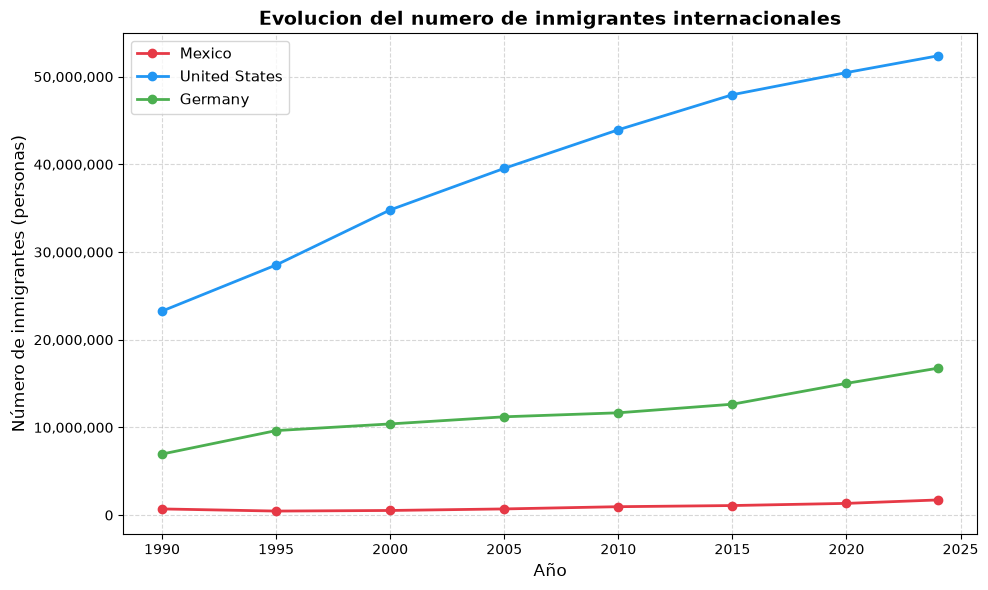

In [17]:
# Pregunta 8
tres_paises = ["Mexico", "United States", "Germany"]
colores = ["#e63946", "#2196F3", "#4CAF50"]
fig, ax = plt.subplots(figsize=(10, 6))
for pais, color in zip(tres_paises, colores):
    df_p = df_paises[df_paises["entity"] == pais].dropna(subset=["valor"]).sort_values("year")
    ax.plot(df_p["year"], df_p["valor"], marker="o", label=pais, color=color, linewidth=2)
ax.set_title("Evolucion del numero de inmigrantes internacionales", fontsize=14, fontweight="bold")
ax.set_xlabel("Año", fontsize=12)
ax.set_ylabel("Número de inmigrantes (personas)", fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()


**Interpretación:** La gráfica muestra a EE.UU. como el destino principal, con Alemania y México en mucha menor escala pero también con tendencias alcistas.

### Pregunta 9 — Visualización integradora


Anio nacimiento 2002 -> mas cercano en dataset: 2000
Anio 2023 -> mas cercano en dataset: 2024


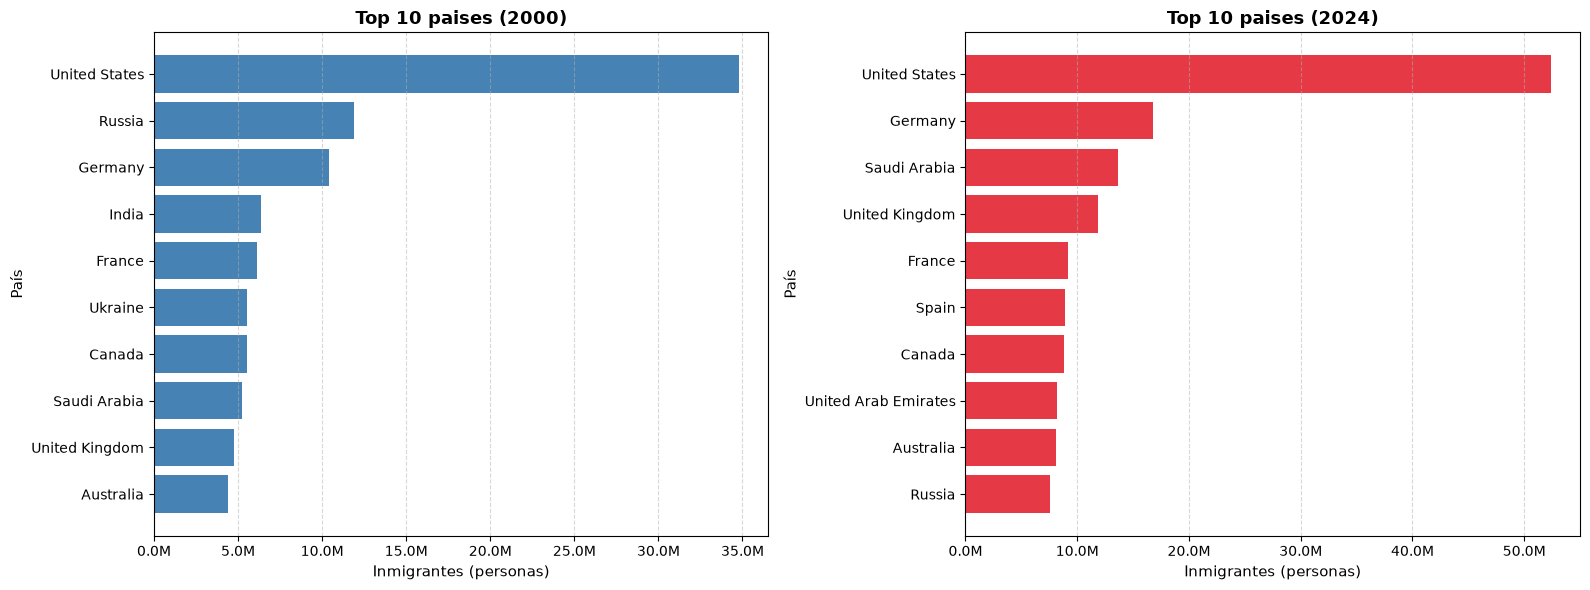

In [18]:
# Pregunta 9
anio_nacimiento = 2002
anios_disponibles = sorted(df_paises.dropna(subset=["valor"])["year"].unique())
anio_nac = min(anios_disponibles, key=lambda y: abs(y - anio_nacimiento))
anio_2023 = min(anios_disponibles, key=lambda y: abs(y - 2023))
print(f"Anio nacimiento 2002 -> mas cercano en dataset: {anio_nac}")
print(f"Anio 2023 -> mas cercano en dataset: {anio_2023}")

def get_top10(anio):
    return (
        df_paises[df_paises["year"] == anio]
        .dropna(subset=["valor"])
        .sort_values("valor", ascending=False)
        .head(10)
    )

top_nac = get_top10(anio_nac)
top_2023 = get_top10(anio_2023)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(top_nac["entity"], top_nac["valor"], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_xlabel("Inmigrantes (personas)", fontsize=11)
axes[0].set_ylabel("País", fontsize=11)
axes[0].set_title(f"Top 10 paises ({anio_nac})", fontsize=13, fontweight="bold")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

axes[1].barh(top_2023["entity"], top_2023["valor"], color="#e63946")
axes[1].invert_yaxis()
axes[1].set_xlabel("Inmigrantes (personas)", fontsize=11)
axes[1].set_ylabel("País", fontsize=11)
axes[1].set_title(f"Top 10 paises ({anio_2023})", fontsize=13, fontweight="bold")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
axes[1].grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


**Interpretación:** El top 10 muestra cambios en las posiciones y un aumento generalizado de cifras absolutas entre ambos años.

## 5. Conclusión general

El dataset revela la concentración de la inmigración en países desarrollados y de altos ingresos. La principal limitación es que se trata de valores absolutos y no relativos a la población, además de tener datos únicamente cada 5 años. En un análisis futuro sería útil cruzar los datos con indicadores como PIB y población total.

## 6. Entrega

1. Verifica que el notebook corra completo de arriba hacia abajo sin errores (`Kernel > Restart & Run All`).
2. Guarda el archivo con el nombre: `apellido_nombre_examen_parcial1.ipynb`.
3. Súbelo al repositorio de GitHub del curso, en una carpeta para este examen.
4. Comparte el link de tu repo y envía una copia del notebook por Teams.
